In [166]:
# plot distributions of population parameters on the sky
import numpy as np
import pandas as pd
from matplotlib import pyplot
import healpy
print(healpy.__version__)

import gammapy
#from gammapy.datasets import MapDataset
#from gammapy.makers import MapDatasetMaker, SafeMaskMaker
from gammapy.maps import HpxGeom, HpxNDMap


import os
import sys
if '../../lib/' not in sys.path:
    sys.path.append('../../lib/')
import dio3
import multi_fgl_utils as util
import plot_util as putil


1.16.6


In [168]:
if 1:
    import importlib
    importlib.reload(util);
    importlib.reload(putil);


In [148]:
def get_xyz(df):
    res = np.zeros((3, len(df)))
    res[2] = df['sin(GLAT)']
    cos_glat = np.sqrt(1. - res[2]**2)
    res[0] = cos_glat * df['cos(GLON)']
    res[1] = cos_glat * df['sin(GLON)']
    return res

def cls2label(cls):
    label = cls[0]
    for cl in cls[1:]:
        label += ', %s' % cl
    return label

def right_arrow():
    return '\u2192'


In [149]:
save_plots = 1
save_png = 0
copy2tex = 1

script_fn = 'fermi_multiclass/notebooks/pop_studies/sky_maps.ipynb'
fig_meta = {'Author': 'Dmitry Malyshev', 'Subject': script_fn}


In [150]:
# parameters
order = 7
nside = int(2**order)
npix = healpy.nside2npix(nside)
pix_area_sr = healpy.nside2pixarea(nside)
pix_area_deg2 = pix_area_sr/np.deg2rad(1.)**2
pix_size_deg = np.rad2deg(healpy.nside2resol(nside))
#sm_radius = pix_size_deg
sm_radius = 2.
sigma_sm = np.deg2rad(sm_radius)
print(nside)
plot_var = 'density'
#plot_var = 'LP_index1000MeV'

# select the catalog and the case
cat_name = '4FGL-DR4' # '4FGL-DR3'
if cat_name == '4FGL-DR4':
    baseline_case = '4FGL-DR4_GMM_RF'
    case = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp' 
    #case = '4FGL-DR4_GMM_RF_no_bcu_spp' 
    #baseline_case = '4FGL-DR4_GMM_RF'
    #case = '4FGL-DR4_GMM_RF' # '4FGL-DR4_GMM_RF_no_prune'
    
baseline = (case == baseline_case)
root_folder = '../../'
config_folder = root_folder + 'config/'

# generic inputs
cdict = util.get_config_dict(baseline_case=baseline_case, 
                             case=case, 
                             folder=config_folder)

cdict['root_folder'] = root_folder
folder_in = cdict['root_folder'] + cdict.get('folder_in', 'data_in/')
folder_out = cdict.get('folder_out', root_folder + 'data_out/')
folder = folder_out
Eind = int(cdict.get('Eind', 1000))
class_name = cdict.get('class_name', 'CLASS1')

cat_folder = '%s/results/%s_probabilistic_catalogs/' % (cdict['root_folder'], util.get_cat_descr(cdict))
cat_fn = cat_folder + util.get_cat_descr(cdict) + '_prob_cat.csv'
cat_df = pd.read_csv(cat_fn, index_col=0)

summary_fn = cat_fn.replace('prob_cat.csv', 'summary.csv')
summary_df = pd.read_csv(summary_fn, index_col=0)

assoc_sources = cdict.get('assoc_sources', 'all_assoc')
sep_model = cdict.get('sep_model', 'GMM')
tree_alg = sep_model
#sep_model = 'RF' # 'GMM', 'RF'
nmin = cdict.get('nmin')
if nmin is not None: 
    nmin = int(nmin)
max_depth = int(cdict.get('max_depth', 5))
feature_mode = cdict.get('features', 'all_features')


tree_cat_fn = util.get_tree_cat_fn(cdict)
tree_cat_dict = dio3.loaddict(tree_cat_fn)
if util.exist_internal(tree_cat_dict):
    util.remove_internal(tree_cat_dict)
max_tree_cat_dict = util.tree2max_tree(tree_cat_dict)
dec_tree_cat_dict = util.max_tree2dec_tree(max_tree_cat_dict)
nodes = [str(key) for key in dec_tree_cat_dict.keys()]

        

all_assoc = []
for cls in tree_cat_dict.values():
    all_assoc.extend(cls)

xdf_fn = util.get_xdf_fn(cdict)
xdf = pd.read_csv(xdf_fn, index_col=0)
ns = len(xdf)

all_features = [name for name in xdf.columns if name.find('CLASS') == -1]
if feature_mode == 'all_features':
    features = all_features
elif feature_mode == 'no_coord_features':
    features = [feat for feat in all_features if feat.find('GL') == -1]


nsrc_dict = util.get_nsrc_dict(xdf, class_column=class_name, classes='associated')
nsrc_df = util.nsrc_dict2df(nsrc_dict)

if 0:
    # algorithm description string
    pars_dict = util.pars_dict
    pars_dict['NN']['nfeatures'] = len(features)
    pars_dict['NN']['epochs'] = cdict.get('epochs', 500)
    #alg_descr = util.get_alg_descr(cdict, pars_dict=pars_dict)

alg_descr = util.get_cat_descr(cdict)

plots_folder = '../../plots/pop_study/%s/sky_maps/' % (alg_descr)
if not os.path.isdir(plots_folder):
    os.makedirs(plots_folder)
    
if copy2tex:
    plots_folder_paper = '/Users/Dmitry/Work/Fermi/fermi_multiclass_papers/4_msp_multi_gce\
/msp_multi_gce_git_PRD/plots/main/sky_maps/'
    if not os.path.isdir(plots_folder_paper):
        os.mkdir(plots_folder_paper)

print(plots_folder)
if 0:
    folder_in = '../../results/4FGL-DR3_probabilistic_classification/'
    #fn = folder_in + '4FGL-DR3_5class_RF_nmin60_no_bcu_spp_prob_cat.csv'
    fn = folder_in + '4FGL-DR3_5class_RF_nmin60_no_bcu_spp_no_coord_features_prob_cat.csv'
    #folder = '../../data_out/'
    #tree_cat_fn = folder + 'tree_cat_nmin60_RF_no_bcu_spp.yaml'

128
../../plots/pop_study/4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features/sky_maps/


In [151]:
if 0:
    # download the cat tree (future - summary file)
    tree_cat_dict = dio3.loaddict(tree_cat_fn)
    nclasses = len(tree_cat_dict)
    max_tree_cat_dict = util.tree2max_tree(tree_cat_dict)
    dec_tree_cat_dict = util.max_tree2dec_tree(max_tree_cat_dict)
    dec_tree_cat_dict

In [152]:
if 0:
    # download the prob catalog
    cat_df = pd.read_csv(fn, index_col=0)
    print(cat_df.columns)
    all_assoc = []
    for cls in tree_cat_dict.values():
        all_assoc.extend(cls)    
    class_name = 'CLASS1'
    
assoc_mask = util.get_cl_mask(all_assoc, cat_df, cname=class_name)    
unas_type = 'unas' # 'unas', 'bcu', 'spp', 'all_not_assoc'

if unas_type == 'all_not_assoc':
    unas_mask = ~assoc_mask
    unas_label = 'unas, unk, bcu, spp'
else:
    unas_mask = util.get_cl_mask([unas_type], cat_df, cname=class_name)
    unas_label = unas_type
#mask = np.ones(len(cat_df), dtype=bool)
plot_unas = 1
if plot_unas:
    mask = unas_mask
    label = unas_label + ' -> '
    descr_str = alg_descr + '_' + unas_type
else:
    mask = assoc_mask
    label = 'Assoc '
    descr_str = alg_descr + '_assoc'
    

In [153]:
# select sources (cuts?)

In [154]:
# coordinates of sources
x, y, z = get_xyz(cat_df)
hind = healpy.vec2pix(nside, x, y, z, nest=False)[mask]
hind_uniq = list(set(hind))

In [185]:
putil.setup_figure_pars({'fig_size':[12, 8], 
                         'axes.titlesize': 24,
                         'xtick.labelsize':18., 
                         'top':0.92, 
                         'bottom':0.0, 
                         'left':0.05, 
                         'right':0.95, 
                         'font.size': 18})
cmap='viridis'
smooth = True

save figure to file: ../../plots/pop_study/4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features/sky_maps/sky_map_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_unas_density_node1.pdf
cp ../../plots/pop_study/4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features/sky_maps/sky_map_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_unas_density_node1.pdf /Users/Dmitry/Work/Fermi/fermi_multiclass_papers/4_msp_multi_gce/msp_multi_gce_git_PRD/plots/main/sky_maps/sky_map_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_unas_density_node1.pdf
save figure to file: ../../plots/pop_study/4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features/sky_maps/sky_map_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_unas_density_node2.pdf
cp ../../plots/pop_study/4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features/sky_maps/sky_map_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_unas_density_node2.pdf /Users/Dmitry/Work/Fermi/fermi_multiclass_papers/4_msp_multi_gce/msp_mu

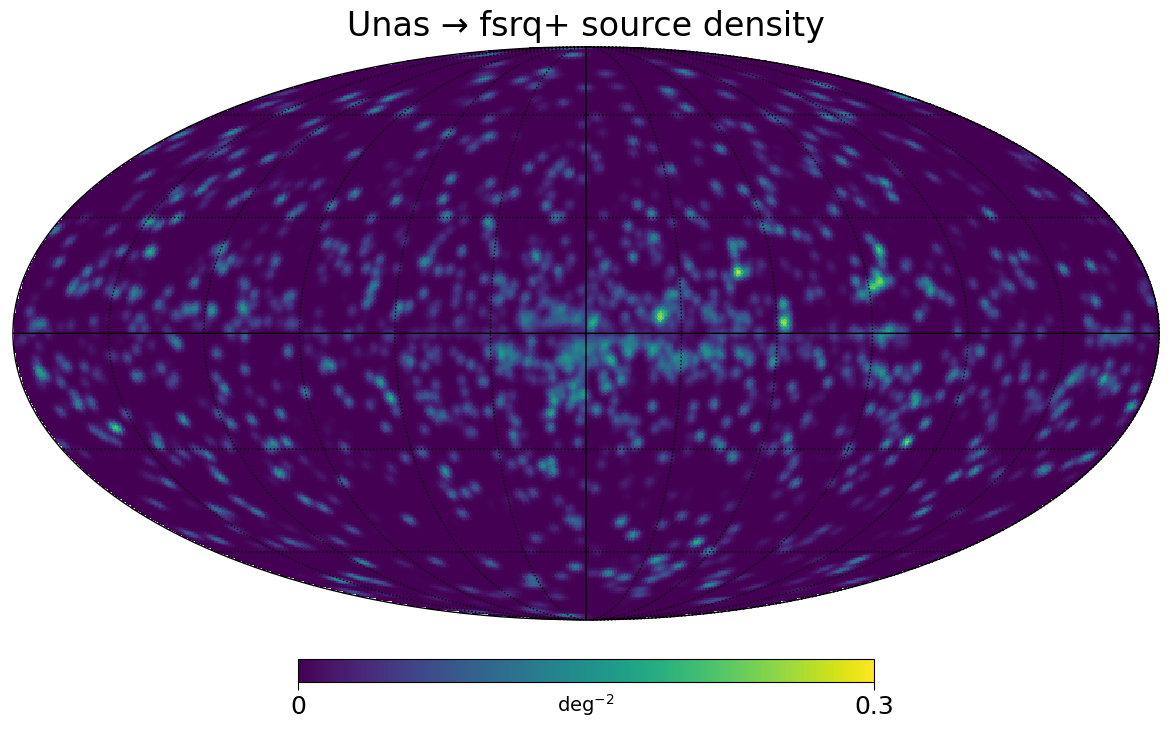

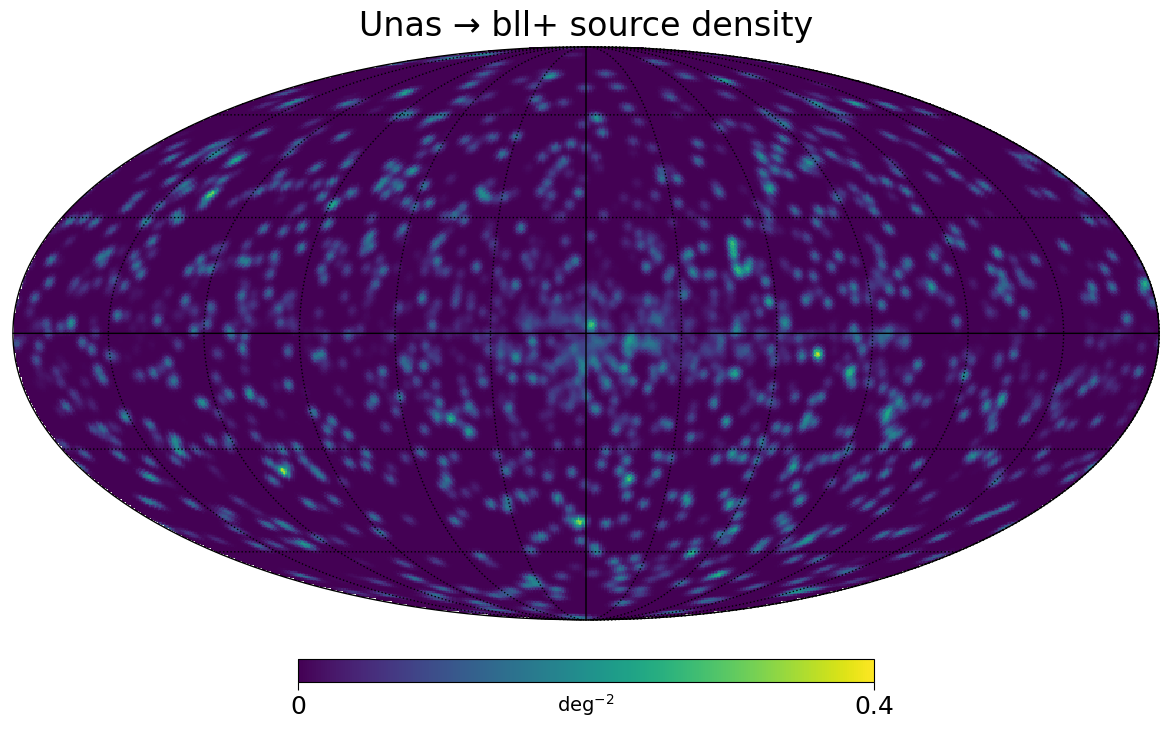

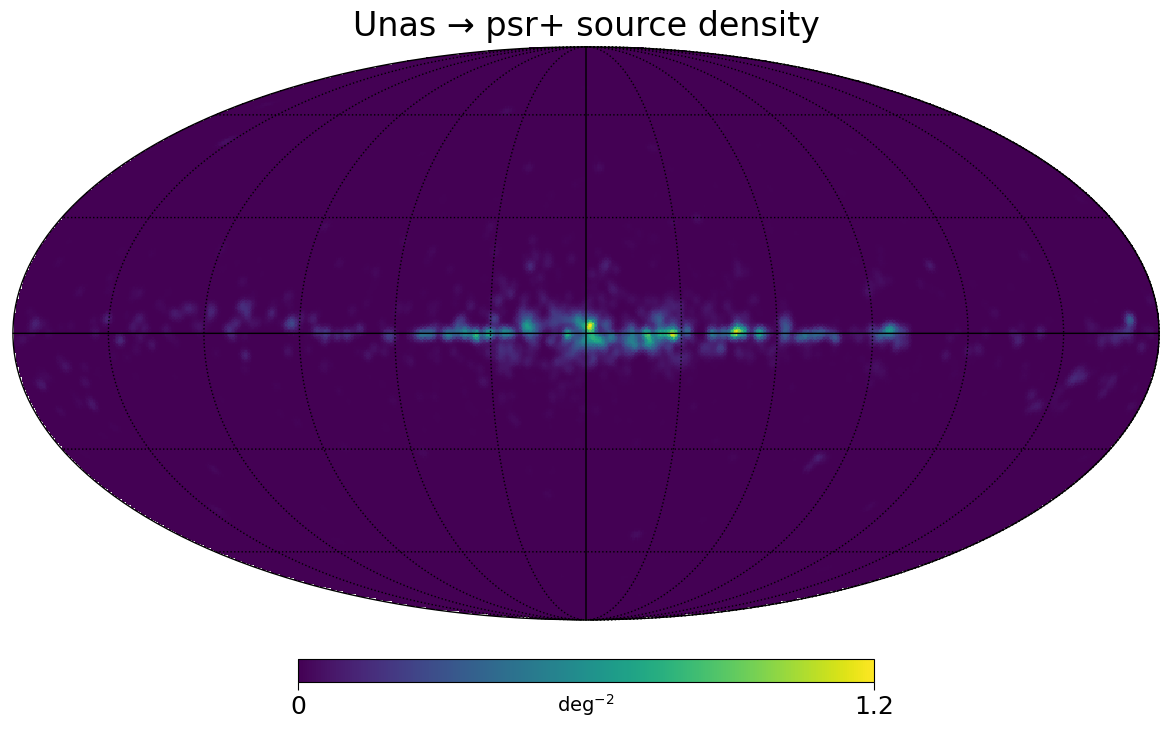

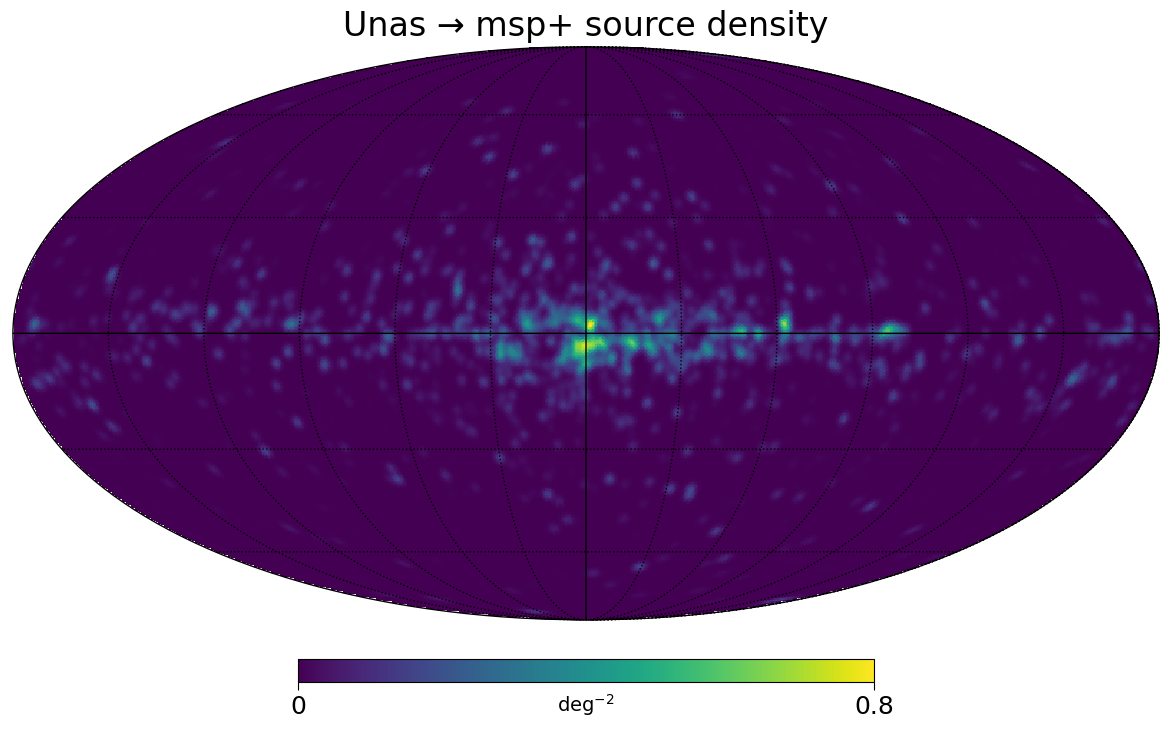

In [186]:
# determine values

for gind in dec_tree_cat_dict.keys():
    clabel = util.get_max_class(dec_tree_cat_dict[gind], nsrc_df)
    weights = cat_df['%i_RF' % gind][mask]
    if plot_var == 'density':
        values = weights
    else:
        values = weights * cat_df[plot_var][mask]
    hmap = np.zeros(npix)
    
    
    for i in hind_uniq:
        if plot_var == 'density':
            hmap[i] = np.sum(weights[i == hind]) / pix_area_deg2 #pix_area_sr
        else:
            hmap[i] = np.sum(values[i == hind]) / np.sum(weights[i == hind])
    if smooth:
        sigma_sm = np.deg2rad(1.)
        hmap = healpy.smoothing(hmap, sigma=sigma_sm)
    geom = HpxGeom(nside, frame='galactic', nest=False)
    hpmap = HpxNDMap(geom, hmap, unit='deg-1')
    
    if 0:
        pyplot.figure()
        title = label + cls2label(dec_tree_cat_dict[gind])
        hpmap.plot(cmap=cmap, add_cbar=1, proj='AIT');
        #fig[0].axes[0].set_xticklabels().set_visible(False)


        #pyplot.title(title)
        #fig.colorbar()
    else:
        
        #healpy.mollview(hmap, min=0, max=0.5, notext=0)
        vmax = np.around(np.max(hmap), decimals=1)
        fig = pyplot.figure()
        healpy.mollview(hmap, fig=fig, min=0, max=vmax, unit=r'${\rm deg}^{-2}$')
        healpy.graticule(dpar=30, dmer=30)
        pyplot.title('%s %s %s+ source density' % (unas_label.capitalize(), right_arrow(), clabel))
        
    if save_plots:
        fn = plots_folder + 'sky_map_%s_%s_node%s.pdf' % (descr_str, plot_var, gind)
        print('save figure to file: %s' % (fn))
        pyplot.savefig(fn, metadata=fig_meta)
        if save_png:
            fn_png = fn.replace('.pdf', '.png')
            pyplot.savefig(fn_png)
        if copy2tex:
            fn_paper = fn.replace(plots_folder, plots_folder_paper)
            cmd = 'cp %s %s' % (fn, fn_paper)
            print(cmd)
            os.system(cmd)



In [171]:
healpy.mollview?